In [1]:

from pathlib import Path
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Рабочая папка
WORK_DIR = Path(r"D:\Downloads\customers (1)")
os.chdir(WORK_DIR)

# Загрузка исходных данных
csv_path = WORK_DIR / "customers.csv"

if not csv_path.exists():
    raise FileNotFoundError(f"Файл не найден: {csv_path}")

df = pd.read_csv(csv_path)

print("Данные успешно загружены!")
print("Размер набора данных:", df.shape)
display(df.head())

# Признаки, использованные в предыдущей практике
feature_columns = [
    "Age",
    "Education",
    "YearsEmployed",
    "Income",
    "CardDebt",
    "OtherDebt",
    "DebtIncomeRatio"
]

# Проверка наличия столбцов
missing_columns = [
    col for col in feature_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Отсутствуют столбцы: {missing_columns}")

# Выбор признаков и преобразование в числовой формат
data = df[feature_columns].copy()

for col in feature_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Обработка пропусков медианой
data = data.fillna(data.median())

# Стандартизация признаков
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("\nПодготовка завершена.")
print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])
print("Пропусков после обработки:", np.isnan(X).sum())
print("Используемые признаки:", feature_columns)


Данные успешно загружены!
Размер набора данных: (850, 10)


,Row,CustomerId,Age,Education,YearsEmployed,Income,CardDebt,OtherDebt,Defaulted,DebtIncomeRatio
0,0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,4,5,47,1,31,253,9.308,8.908,0.0,7.2



Подготовка завершена.
Количество объектов: 850
Количество признаков: 7
Пропусков после обработки: 0
Используемые признаки: ['Age', 'Education', 'YearsEmployed', 'Income', 'CardDebt', 'OtherDebt', 'DebtIncomeRatio']


Обработка метода: Single linkage — ближайший сосед


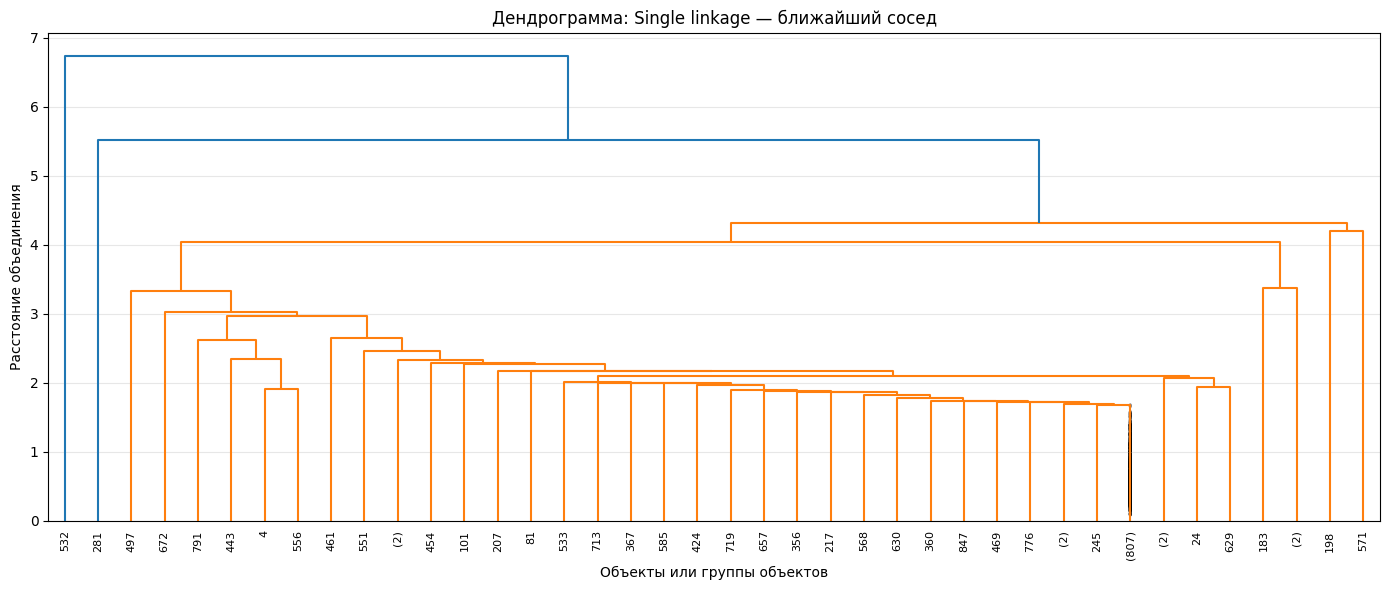

Дендрограмма сохранена: hierarchical_results\dendrogram_single.png
Обработка метода: Complete linkage — дальний сосед


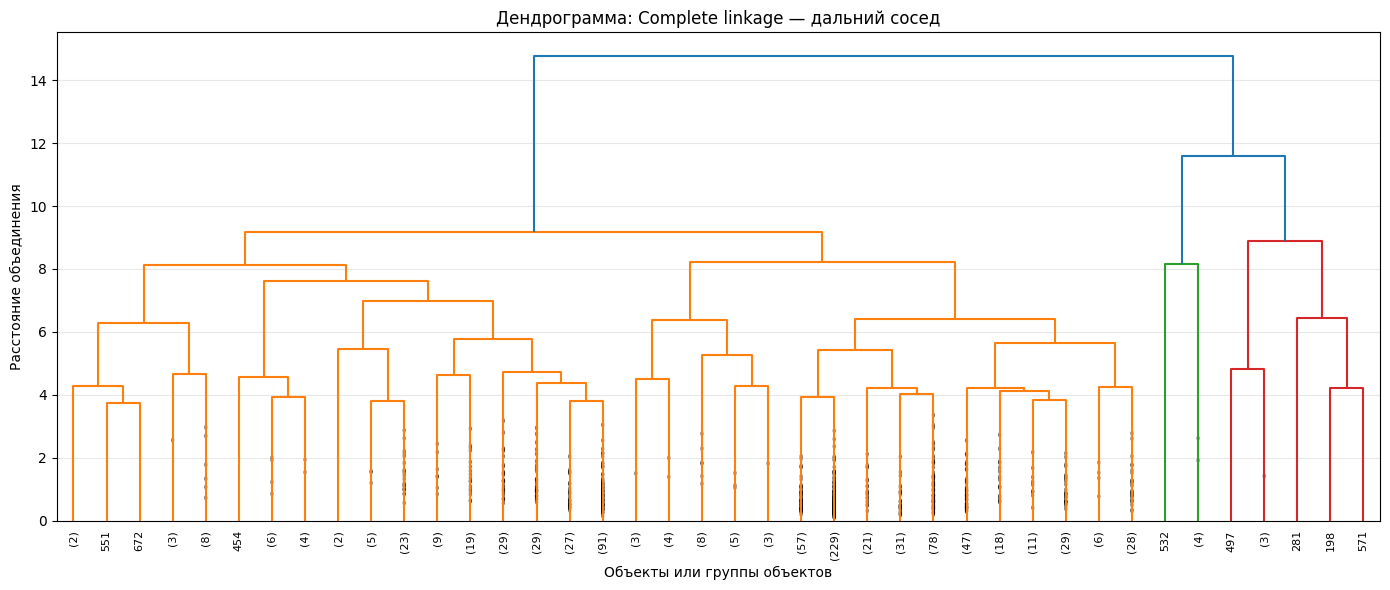

Дендрограмма сохранена: hierarchical_results\dendrogram_complete.png
Обработка метода: Group average — среднее расстояние


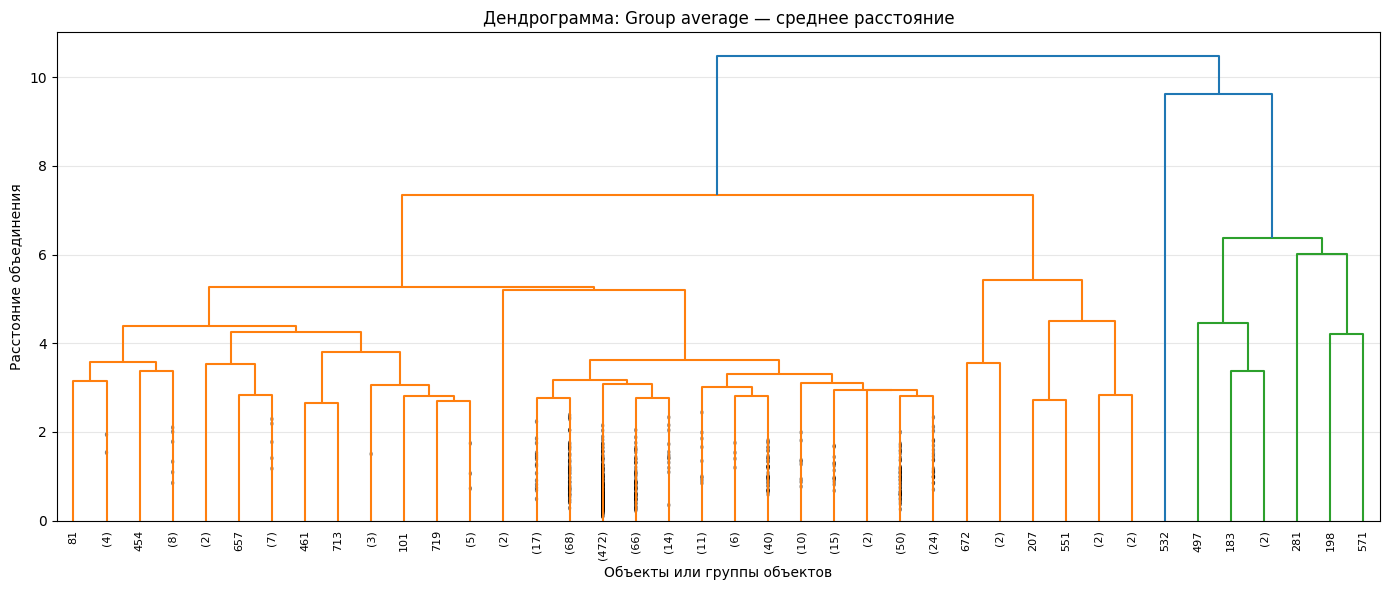

Дендрограмма сохранена: hierarchical_results\dendrogram_average.png
Обработка метода: Ward distance — метод Уорда


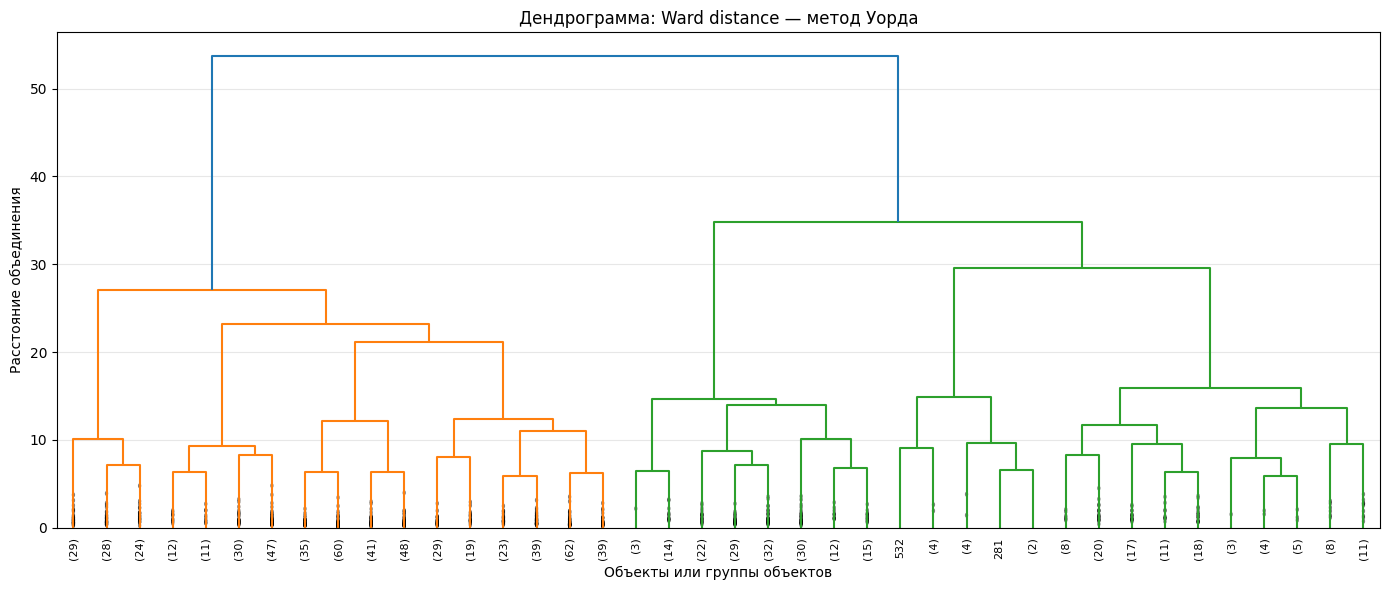

Дендрограмма сохранена: hierarchical_results\dendrogram_ward.png

Все четыре дендрограммы построены.


In [2]:
linkage_methods = {
    "single": "Single linkage — ближайший сосед",
    "complete": "Complete linkage — дальний сосед",
    "average": "Group average — среднее расстояние",
    "ward": "Ward distance — метод Уорда"
}

RESULTS_DIR = Path("hierarchical_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

linkage_results = {}

for method, description in linkage_methods.items():
    print(f"Обработка метода: {description}")

    Z = linkage(
        X,
        method=method,
        metric="euclidean",
        optimal_ordering=False
    )

    linkage_results[method] = Z

    plt.figure(figsize=(14, 6))

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=40,
        show_leaf_counts=True,
        leaf_rotation=90,
        leaf_font_size=8,
        show_contracted=True
    )

    plt.title(f"Дендрограмма: {description}")
    plt.xlabel("Объекты или группы объектов")
    plt.ylabel("Расстояние объединения")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    # Сохраняем рисунок
    filename = RESULTS_DIR / f"dendrogram_{method}.png"
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

    print(f"Дендрограмма сохранена: {filename}")

print("\nВсе четыре дендрограммы построены.")


In [3]:


k_compare = 3
comparison_results = []
cluster_labels = {}

for method, Z in linkage_results.items():
    # Получаем ровно k_compare кластеров из дендрограммы
    labels = fcluster(
        Z,
        t=k_compare,
        criterion="maxclust"
    )

    cluster_labels[method] = labels

    # Коэффициент силуэта
    silhouette = silhouette_score(
        X,
        labels,
        metric="euclidean"
    )

    # Количество реально получившихся кластеров
    n_clusters = len(np.unique(labels))

    comparison_results.append({
        "Метод": linkage_methods[method],
        "Количество кластеров": n_clusters,
        "Коэффициент силуэта": silhouette
    })

comparison_df = pd.DataFrame(comparison_results)

print("Сравнение методов при k =", k_compare)
display(
    comparison_df.sort_values(
        "Коэффициент силуэта",
        ascending=False
    ).reset_index(drop=True)
)

# Сравнение совпадения назначений объектов между методами
agreement_records = []

methods = list(linkage_methods.keys())

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):
        method_a = methods[i]
        method_b = methods[j]

        ari = adjusted_rand_score(
            cluster_labels[method_a],
            cluster_labels[method_b]
        )

        agreement_records.append({
            "Метод 1": method_a,
            "Метод 2": method_b,
            "Adjusted Rand Index": ari
        })

agreement_df = pd.DataFrame(agreement_records)

print("\nСходство разбиений между методами:")
display(agreement_df)

# Сохраняем результаты
comparison_df.to_csv(
    RESULTS_DIR / "method_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

agreement_df.to_csv(
    RESULTS_DIR / "method_agreement.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nТаблицы сравнения сохранены в:", RESULTS_DIR.resolve())


Сравнение методов при k = 3


,Метод,Количество кластеров,Коэффициент силуэта
0,Single linkage — ближайший сосед,3,0.725613
1,Group average — среднее расстояние,3,0.671068
2,Complete linkage — дальний сосед,3,0.645996
3,Ward distance — метод Уорда,3,0.246921



Сходство разбиений между методами:


,Метод 1,Метод 2,Adjusted Rand Index
0,single,complete,0.280429
1,single,average,0.396173
2,single,ward,0.007233
3,complete,average,0.796073
4,complete,ward,0.043853
5,average,ward,0.029162



Таблицы сравнения сохранены в: D:\Downloads\customers (1)\hierarchical_results


In [7]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

k_compare = 3


model_kmeans = KMeans(
    n_clusters=k_compare,
    random_state=42,
    n_init=10
)
labels_kmeans = model_kmeans.fit_predict(X)


def run_kmedoids(X, k, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    n = len(X)

    # Матрица евклидовых расстояний
    D = squareform(pdist(X, metric="euclidean"))

    # Начальные медоиды — реальные объекты
    medoids = rng.choice(n, size=k, replace=False)

    for _ in range(max_iter):
        labels = np.argmin(D[:, medoids], axis=1)
        new_medoids = medoids.copy()

        for cluster_id in range(k):
            members = np.flatnonzero(labels == cluster_id)

            if len(members) == 0:
                continue

            # Медоид минимизирует сумму расстояний
            # до остальных объектов своего кластера
            costs = D[np.ix_(members, members)].sum(axis=1)
            new_medoids[cluster_id] = members[np.argmin(costs)]

        if np.array_equal(medoids, new_medoids):
            break

        medoids = new_medoids

    labels = np.argmin(D[:, medoids], axis=1)

    return labels

labels_kmedoids = run_kmedoids(
    X, k=k_compare, random_state=42
)


all_labels = {
    "k-Means": labels_kmeans,
    "k-Medoids": labels_kmedoids,
    **{
        method: labels
        for method, labels in cluster_labels.items()
    }
}

summary = []

for name, labels in all_labels.items():
    summary.append({
        "Алгоритм": name,
        "Количество кластеров": len(np.unique(labels)),
        "Коэффициент силуэта": silhouette_score(X, labels)
    })

summary_df = pd.DataFrame(summary).sort_values(
    "Коэффициент силуэта",
    ascending=False
).reset_index(drop=True)

print("Сравнение качества кластеризации при k = 3:")
display(summary_df)

ari_matrix = pd.DataFrame(
    index=all_labels.keys(),
    columns=all_labels.keys(),
    dtype=float
)

for name_a, labels_a in all_labels.items():
    for name_b, labels_b in all_labels.items():
        ari_matrix.loc[name_a, name_b] = adjusted_rand_score(
            labels_a, labels_b
        )

print("\nМатрица сходства разбиений (ARI):")
display(ari_matrix.round(3))


RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    RESULTS_DIR / "all_algorithms_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

ari_matrix.to_csv(
    RESULTS_DIR / "all_algorithms_ari.csv",
    encoding="utf-8-sig"
)

print("\nСравнение завершено.")
print("Результаты сохранены в:", RESULTS_DIR.resolve())


Сравнение качества кластеризации при k = 3:


,Алгоритм,Количество кластеров,Коэффициент силуэта
0,single,3,0.725613
1,average,3,0.671068
2,complete,3,0.645996
3,k-Medoids,3,0.287711
4,ward,3,0.246921
5,k-Means,3,0.233602



Матрица сходства разбиений (ARI):


,k-Means,k-Medoids,single,complete,average,ward
k-Means,1.000,0.313,0.006,0.038,0.025,0.547
k-Medoids,0.313,1.000,0.011,0.066,0.044,0.510
single,0.006,0.011,1.000,0.280,0.396,0.007
complete,0.038,0.066,0.280,1.000,0.796,0.044
average,0.025,0.044,0.396,0.796,1.000,0.029
ward,0.547,0.510,0.007,0.044,0.029,1.000



Сравнение завершено.
Результаты сохранены в: D:\Downloads\customers (1)\hierarchical_results


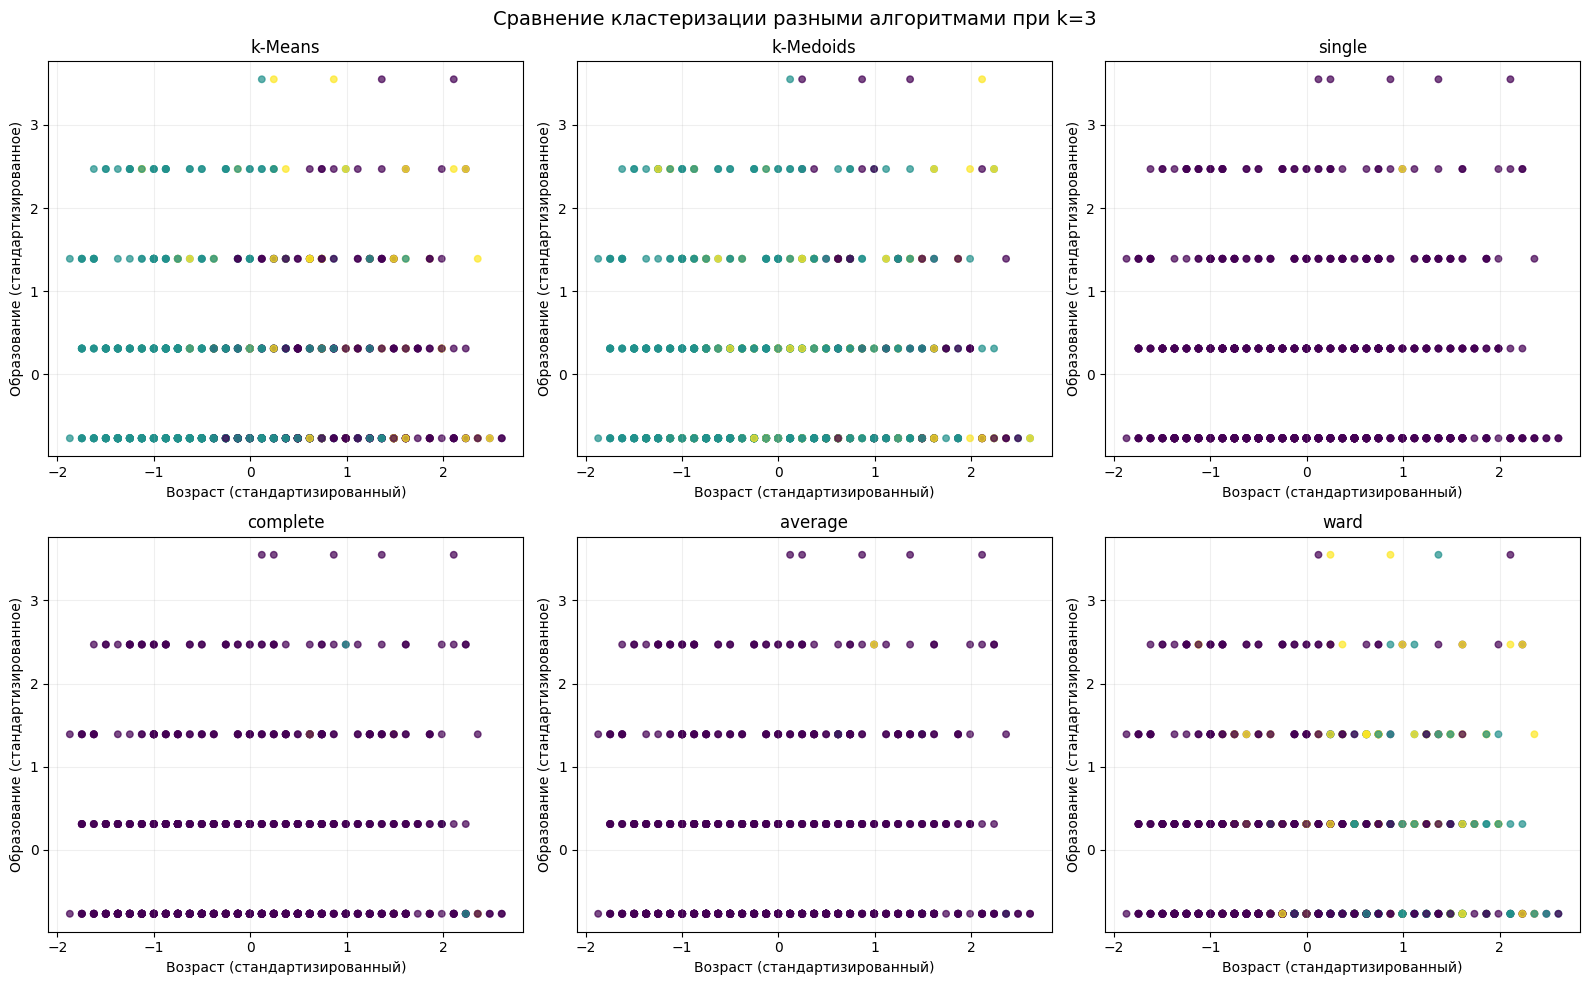

Назначения кластеров сохранены.
График сравнения сохранён.
Все материалы находятся в: D:\Downloads\customers (1)\hierarchical_results


In [8]:

# Сохраняем назначения кластеров для всех алгоритмов
assignments = pd.DataFrame({
    "object_index": np.arange(len(X))
})

for name, labels in all_labels.items():
    assignments[name] = labels

assignments.to_csv(
    RESULTS_DIR / "cluster_assignments_k3.csv",
    index=False,
    encoding="utf-8-sig"
)

# Строим точечные диаграммы для первых двух признаков
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

algorithm_names = list(all_labels.keys())

for ax, name in zip(axes, algorithm_names):
    labels = all_labels[name]

    ax.scatter(
        X[:, 0],
        X[:, 1],
        c=labels,
        cmap="viridis",
        s=22,
        alpha=0.7
    )

    ax.set_title(name)
    ax.set_xlabel("Возраст (стандартизированный)")
    ax.set_ylabel("Образование (стандартизированное)")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Сравнение кластеризации разными алгоритмами при k=3",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "clustering_comparison_k3.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Назначения кластеров сохранены.")
print("График сравнения сохранён.")
print("Все материалы находятся в:", RESULTS_DIR.resolve())


In [9]:

cluster_sizes = []

for algorithm_name, labels in all_labels.items():
    unique_labels, counts = np.unique(
        labels,
        return_counts=True
    )

    print(f"\n{algorithm_name}")
    for cluster_id, count in zip(unique_labels, counts):
        print(
            f"Кластер {cluster_id}: {count} объектов "
            f"({count / len(labels) * 100:.1f}%)"
        )

        cluster_sizes.append({
            "Алгоритм": algorithm_name,
            "Кластер": int(cluster_id),
            "Количество объектов": int(count),
            "Доля, %": round(count / len(labels) * 100, 2)
        })

cluster_sizes_df = pd.DataFrame(cluster_sizes)

cluster_sizes_df.to_csv(
    RESULTS_DIR / "cluster_sizes_k3.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nСводная таблица распределения:")
display(cluster_sizes_df)



k-Means
Кластер 0: 286 объектов (33.6%)
Кластер 1: 489 объектов (57.5%)
Кластер 2: 75 объектов (8.8%)

k-Medoids
Кластер 0: 82 объектов (9.6%)
Кластер 1: 631 объектов (74.2%)
Кластер 2: 137 объектов (16.1%)

single
Кластер 1: 848 объектов (99.8%)
Кластер 2: 1 объектов (0.1%)
Кластер 3: 1 объектов (0.1%)

complete
Кластер 1: 838 объектов (98.6%)
Кластер 2: 5 объектов (0.6%)
Кластер 3: 7 объектов (0.8%)

average
Кластер 1: 842 объектов (99.1%)
Кластер 2: 7 объектов (0.8%)
Кластер 3: 1 объектов (0.1%)

ward
Кластер 1: 576 объектов (67.8%)
Кластер 2: 157 объектов (18.5%)
Кластер 3: 117 объектов (13.8%)

Сводная таблица распределения:


,Алгоритм,Кластер,Количество объектов,"Доля, %"
0,k-Means,0,286,33.65
1,k-Means,1,489,57.53
2,k-Means,2,75,8.82
3,k-Medoids,0,82,9.65
4,k-Medoids,1,631,74.24
5,k-Medoids,2,137,16.12
6,single,1,848,99.76
7,single,2,1,0.12
8,single,3,1,0.12
9,complete,1,838,98.59


In [ ]:

from scipy.cluster.hierarchy import fcluster
import numpy as np

hierarchical_labels_k3 = {}

for method, Z in linkage_results.items():
    heights = np.unique(Z[:, 2])
    found = False

    # Проверяем промежутки между соседними высотами
    for i in range(len(heights) - 1):
        threshold = (heights[i] + heights[i + 1]) / 2

        labels = fcluster(
            Z,
            t=threshold,
            criterion="distance"
        )

        if len(np.unique(labels)) == 3:
            found = True
            break

    if not found:
        print(f"\n{method}: порог для трёх кластеров не найден.")
        continue

    hierarchical_labels_k3[method] = labels
    unique_labels, counts = np.unique(labels, return_counts=True)

    print(f"\nМетод: {method}")
    print(f"Порог среза: {threshold:.4f}")
    print(f"Количество кластеров: {len(unique_labels)}")

    for cluster_id, count in zip(unique_labels, counts):
        print(
            f"Кластер {cluster_id}: {count} объектов "
            f"({count / len(X) * 100:.2f}%)"
        )

print("\nПроверка завершена.")



Метод: single
Порог среза: 4.9206
Количество кластеров: 3
Кластер 1: 848 объектов (99.76%)
Кластер 2: 1 объектов (0.12%)
Кластер 3: 1 объектов (0.12%)

Метод: complete
Порог среза: 10.3820
Количество кластеров: 3
Кластер 1: 838 объектов (98.59%)
Кластер 2: 5 объектов (0.59%)
Кластер 3: 7 объектов (0.82%)

Метод: average
Порог среза: 8.4760
Количество кластеров: 3
Кластер 1: 842 объектов (99.06%)
Кластер 2: 7 объектов (0.82%)
Кластер 3: 1 объектов (0.12%)

Метод: ward
Порог среза: 32.1902
Количество кластеров: 3
Кластер 1: 576 объектов (67.76%)
Кластер 2: 157 объектов (18.47%)
Кластер 3: 117 объектов (13.76%)

Проверка завершена.


In [12]:


# Объединяем качество кластеризации и распределение объектов
final_summary = summary_df.copy()

# Добавляем количество объектов в самом крупном кластере
largest_cluster = []

for algorithm_name, labels in all_labels.items():
    counts = pd.Series(labels).value_counts()
    largest_cluster.append({
        "Алгоритм": algorithm_name,
        "Размер крупнейшего кластера": int(counts.max()),
        "Доля крупнейшего кластера, %": round(
            counts.max() / len(labels) * 100, 2
        )
    })

largest_df = pd.DataFrame(largest_cluster)

final_summary = final_summary.merge(
    largest_df,
    on="Алгоритм",
    how="left"
)

final_summary = final_summary.sort_values(
    "Коэффициент силуэта",
    ascending=False
).reset_index(drop=True)

print("ИТОГОВОЕ СРАВНЕНИЕ АЛГОРИТМОВ, k = 3")
display(final_summary.round(4))

final_summary.to_csv(
    RESULTS_DIR / "final_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# Сохраняем описание используемых параметров
parameters = pd.DataFrame([
    {"Параметр": "Набор данных", "Значение": "customers.csv"},
    {"Параметр": "Количество объектов", "Значение": len(X)},
    {"Параметр": "Количество признаков", "Значение": X.shape[1]},
    {"Параметр": "Количество кластеров", "Значение": 3},
    {"Параметр": "Расстояние между объектами", "Значение": "Евклидово"},
    {
        "Параметр": "Признаки",
        "Значение": ", ".join(feature_columns)
    }
])

parameters.to_csv(
    RESULTS_DIR / "experiment_parameters.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nИтоговая сводка и параметры сохранены.")
print("Папка с результатами:", RESULTS_DIR.resolve())


ИТОГОВОЕ СРАВНЕНИЕ АЛГОРИТМОВ, k = 3


,Алгоритм,Количество кластеров,Коэффициент силуэта,Размер крупнейшего кластера,"Доля крупнейшего кластера, %"
0,single,3,0.7256,848,99.76
1,average,3,0.6711,842,99.06
2,complete,3,0.6460,838,98.59
3,k-Medoids,3,0.2877,631,74.24
4,ward,3,0.2469,576,67.76
5,k-Means,3,0.2336,489,57.53



Итоговая сводка и параметры сохранены.
Папка с результатами: D:\Downloads\customers (1)\hierarchical_results
